# Wakes: two analytical models against what the farm actually did

Jensen/PARK and Bastankhah & Porté-Agel on the published Penmanshiel layout,
compared sector by sector with the farm efficiency the SCADA implies. The wake
decay constant is fitted on a **validation** window and scored on a later test
window.

These are analytical engineering models, not CFD. The notebook says so once and
then measures how far off they are.

## Setup

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

from pinneapple_systems import wind
from pinneapple_systems.wind import figures

warnings.filterwarnings("ignore", category=FutureWarning)

RAW = Path(os.environ.get("PENMANSHIEL_RAW", Path.home() / "pn-wind-data" / "raw"))
CACHE = Path(os.environ.get("PENMANSHIEL_CACHE", Path.home() / "pn-wind-data" / "cache"))
assert (RAW / "Penmanshiel_WT_static.csv").exists(), (
    f"no Penmanshiel data in {RAW}; see examples/wind_farm_penmanshiel/README.md for the download"
)
RATED, ROTOR, HUB = 2050.0, 82.0, 59.0

In [2]:
layout = wind.static_layout(RAW)
print(layout, "|", layout.installed_capacity_mw, "MW")
nearest = wind.pair_geometry(layout)
pd.DataFrame(nearest)[["turbine", "nearest", "distance_in_diameters", "bearing_deg"]].round(2).head(6)

WindFarmLayout('Penmanshiel', 14 turbines) | 28.7 MW


,turbine,nearest,distance_in_diameters,bearing_deg
0,T01,T02,5.16,310.98
1,T02,T05,4.98,206.33
2,T04,T05,4.87,317.55
3,T05,T06,4.62,313.53
4,T06,T07,4.33,313.80
5,T07,T06,4.33,133.80


## One wake, two shapes

The Jensen wake is a cone with a top-hat profile; the Gaussian one recovers in the
centre faster than at the edge. Both conserve momentum in a depth-averaged sense.

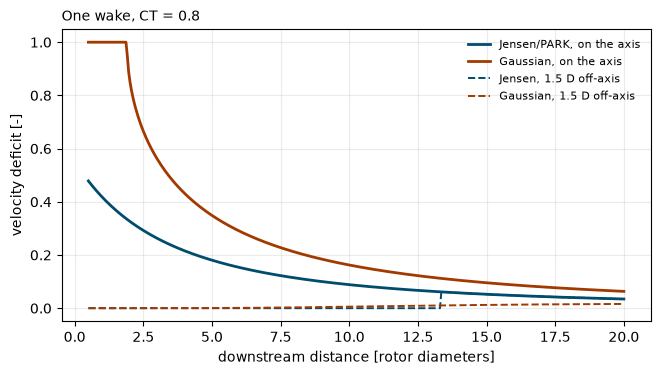

In [3]:
x = np.linspace(0.5, 20, 400) * ROTOR
fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.plot(x / ROTOR, wind.jensen_deficit(x, 0.0, ROTOR, 0.8), lw=2,
        label="Jensen/PARK, on the axis", color="#004c6d")
ax.plot(x / ROTOR, wind.gaussian_deficit(x, 0.0, ROTOR, 0.8), lw=2,
        label="Gaussian, on the axis", color="#a23a00")
ax.plot(x / ROTOR, wind.jensen_deficit(x, 1.5 * ROTOR, ROTOR, 0.8), lw=1.4, ls="--",
        color="#004c6d", label="Jensen, 1.5 D off-axis")
ax.plot(x / ROTOR, wind.gaussian_deficit(x, 1.5 * ROTOR, ROTOR, 0.8), lw=1.4, ls="--",
        color="#a23a00", label="Gaussian, 1.5 D off-axis")
ax.set_xlabel("downstream distance [rotor diameters]")
ax.set_ylabel("velocity deficit [-]")
ax.set_title("One wake, CT = 0.8", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=0.25)
plt.show()

## The whole farm against wind direction

8 m/s from the west: 9.05 MW of 10.43 MW wake-free -> 13.2% loss


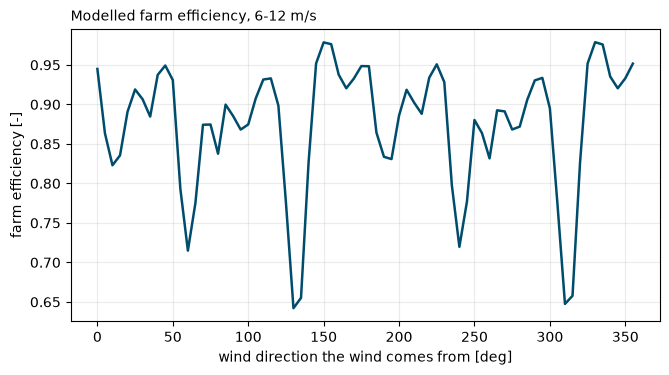

In [4]:
curve = wind.ReferencePowerCurve(RATED, ROTOR).power
result = wind.farm_power(layout, 8.0, 270.0, curve)
print(f"8 m/s from the west: {result.total_power_kw/1000:.2f} MW of "
      f"{result.total_power_no_wake_kw/1000:.2f} MW wake-free "
      f"-> {result.wake_loss_fraction:.1%} loss")

polar = wind.direction_polar(layout, [6.0, 8.0, 10.0, 12.0], curve, n_directions=72)
fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.plot(polar["directions_deg"], polar["efficiencies"], color="#004c6d", lw=1.8)
ax.set_xlabel("wind direction the wind comes from [deg]")
ax.set_ylabel("farm efficiency [-]")
ax.set_title("Modelled farm efficiency, 6-12 m/s", loc="left", fontsize=10)
ax.grid(alpha=0.25)
plt.show()

## What the farm actually did

The comparison is built from metered power only. For each sector, the reference is
the group of three most-upwind turbines; their power is inverted through the
site's curves to a reference speed, and the farm efficiency is observed power over
what every machine would make at that speed. Anemometry is deliberately left out:
nacelle anemometers are not calibrated against each other, and in region 2 a 5 %
speed offset becomes a 15 % power offset.

In [5]:
layout_names = layout.names
farm = wind.load_farm(RAW, turbines=layout_names, cache_dir=CACHE)
farm = wind.add_density_correction(
    farm, elevation_m=float(np.mean([t.elevation for t in layout if t.elevation is not None])))
farm["operating"] = pd.concat([
    pd.Series(wind.operating_mask(g, rated_power_kw=RATED), index=g.index)
    for _, g in farm.groupby("turbine", sort=False)
]).sort_index()

TRAIN_END, VAL_END = pd.Timestamp("2017-07-01"), pd.Timestamp("2017-09-01")
train_rows = farm[farm.timestamp < TRAIN_END]
curves = {}
for name in layout_names:
    g = train_rows[(train_rows.turbine == name) & train_rows.operating]
    curves[name] = wind.fit_binned_curve(g.u_corrected, g.power_kw, cut_out=25.0, min_count=20).power
print("one measured curve per turbine, fitted on the training window only")

one measured curve per turbine, fitted on the training window only


In [6]:
def window(lo, hi):
    part = farm[(farm.timestamp >= lo) & (farm.timestamp < hi)].copy()
    part["operating"] = pd.concat([
        pd.Series(wind.operating_mask(g, rated_power_kw=RATED), index=g.index)
        for _, g in part.groupby("turbine", sort=False)
    ]).sort_index()
    return part

obs_val = wind.farm_efficiency_observed(window(TRAIN_END, VAL_END), layout, curves,
                                        n_sectors=36, speed_edges=(4.0, 11.0, 1.0),
                                        min_samples=40, reference_group=3)
obs_test = wind.farm_efficiency_observed(window(VAL_END, pd.Timestamp("2018-01-01")), layout, curves,
                                         n_sectors=36, speed_edges=(4.0, 11.0, 1.0),
                                         min_samples=40, reference_group=3)
print(f"validation cells {np.isfinite(obs_val.efficiency).sum()}, "
      f"test cells {np.isfinite(obs_test.efficiency).sum()} "
      f"from {obs_test.meta['n_timestamps_used']:,} timestamps")

validation cells 51, test cells 96 from 12,942 timestamps


## Fit one constant on validation, score it on test

The textbook Gaussian constant is 0.0325. A farm with a published layout and
SCADA can measure its own instead — as long as the fit is not then scored on its
own data.

In [7]:
calibration = wind.calibrate_wake_decay(obs_val, layout, curves, kind="gaussian")
print(f"best k* on validation: {calibration['best_k']:.4f} "
      f"(textbook {calibration['textbook_k']:.4f})")
pd.DataFrame(calibration["sweep"]).round(4)

best k* on validation: 0.0900 (textbook 0.0325)


,k,rmse,bias,n_cells
0,0.020,0.1684,-0.1322,51
1,0.030,0.1417,-0.0996,51
2,0.040,0.1228,-0.0740,51
3,0.050,0.1103,-0.0539,51
4,0.060,0.1024,-0.0380,51
5,0.075,0.0961,-0.0193,51
6,0.090,0.0942,-0.0051,51
7,0.110,0.0950,0.0094,51
8,0.130,0.0972,0.0203,51
9,0.160,0.1012,0.0325,51


In [8]:
rows = {}
for label, cfg in [
    ("Gaussian, textbook k*", wind.WakeConfig(kind="gaussian")),
    (f"Gaussian, k*={calibration['best_k']:.3f} fitted", wind.WakeConfig(
        kind="gaussian", k=calibration["best_k"], gaussian_k=calibration["best_k"])),
    ("Jensen, textbook k", wind.WakeConfig(kind="jensen")),
]:
    c = wind.compare_with_model(obs_test, layout, curves, config=cfg)
    model = np.array([np.nan if v is None else v for v in c["model_efficiency"]], dtype=float)
    seen = np.array([np.nan if v is None else v for v in c["observed_efficiency"]], dtype=float)
    rows[label] = {
        "modelled": np.nanmean(model).round(3),
        "observed": np.nanmean(seen).round(3),
        "bias [pp]": round(100 * c["bias"], 1),
        "RMSE": round(c["rmse"], 3),
        "correlation": round(c["correlation"], 2),
    }
pd.DataFrame(rows).T

,modelled,observed,bias [pp],RMSE,correlation
"Gaussian, textbook k*",0.833,0.936,-11.8,0.185,0.17
"Gaussian, k*=0.090 fitted",0.910,0.936,-3.1,0.126,0.16
"Jensen, textbook k",0.840,0.936,-10.7,0.169,0.21


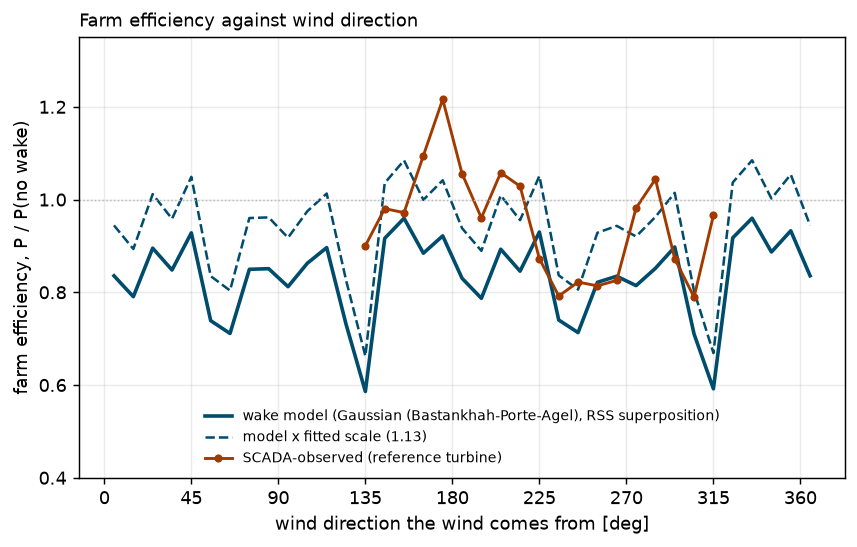

In [9]:
comparison = wind.compare_with_model(obs_test, layout, curves, config=wind.WakeConfig(kind="gaussian"))
fig = figures.plot_wake_polar(obs_test, comparison)
plt.show()

## The same model, in 3D

The twin3d scene carries the plan-view wake footprint on a ground grid, swept over
a full direction cycle. `outputs/wind_farm_demo.mp4` is this scene rendered frame
by frame; here one frame is drawn inline.

24 steps, ground field (24, 3888), 14 turbine sensors


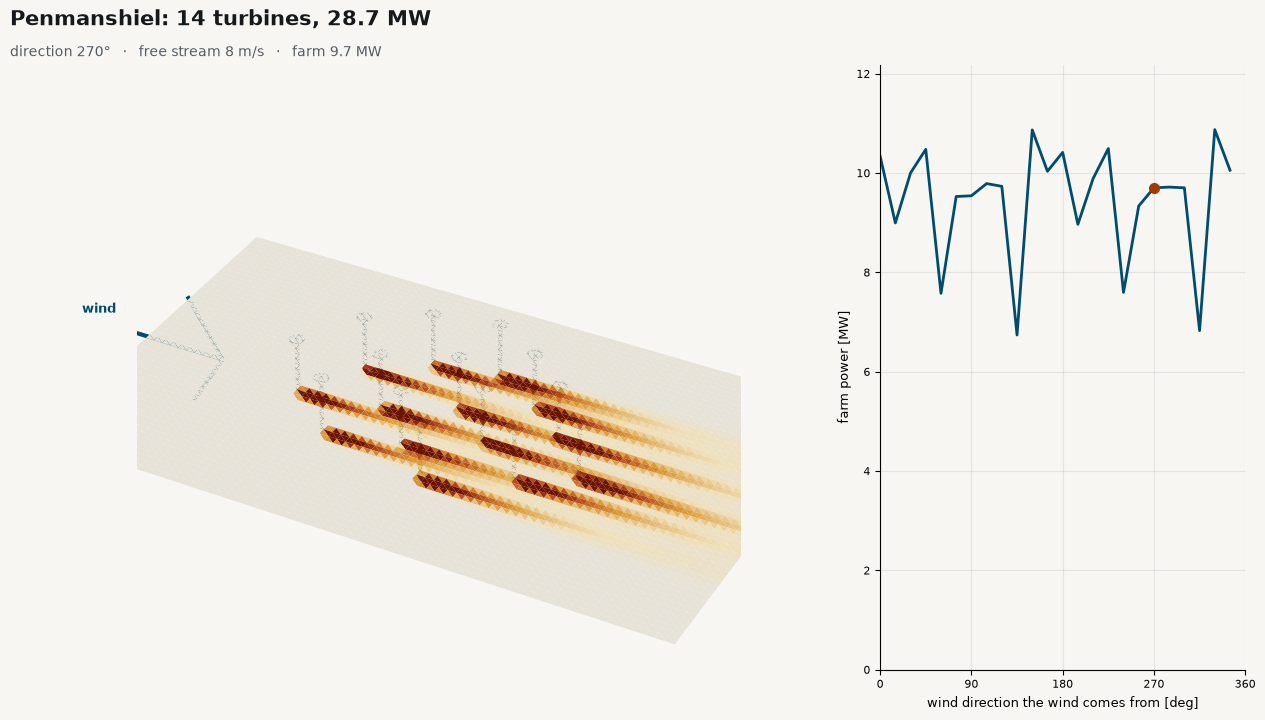

In [10]:
from pinneapple_systems.wind import twin, video

directions = np.arange(0.0, 360.0, 15.0)
scene = twin.build_farm_scene(layout, directions, wind_speed=8.0,
                              power_curves=[curves[n] for n in layout.names], n_x=72, n_y=54)
print(f"{len(directions)} steps, ground field {scene.parts[0].fields['velocity_ratio'].shape}, "
      f"{len(scene.sensors)} turbine sensors")

fig = video.render_frame(scene, layout, 18, wind_speed=8.0,
                         title=f"{layout.name}: {len(layout)} turbines, {layout.installed_capacity_mw:.1f} MW")
plt.show()

### What this does not establish

The observed efficiency is an **upper bound** on wake loss: it absorbs curtailment
that survived the filter, icing, and genuine per-turbine under-performance. The
correlation across sectors is weak, so the model's *direction dependence* is not
reproduced even where its average is. And nothing here is a flow solution.